# 作业 03：NumPy、Matplotlib 与 pandas

`20244080329_吴卓斯_hw03.ipynb`

三部分：用随机矩阵验证半圆定律、实现 Conway 生命游戏、用 pandas 处理 iris 数据。
环境为独立 conda 环境 `exp03`。

## 0. 身份与环境记录

In [1]:
import hashlib
import os
import platform
import uuid
import sys

# 修改为自己的学号
STUDENT_ID = 20244080329

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python]   {sys.version.split()[0]}")

[Conda 环境] exp03
[学号]       20244080329
[机器指纹] 72a4fda4ca0e6d59
[RUN_ID]   20244080329-72a4fda4ca0e6d59
[Python]   3.11.17


## 一、半圆定律

对 $n\times n$ 的 Wigner 矩阵（上三角独立取 $N(0, 1/n)$，再对称地补出下三角），
当 $n$ 变大时，特征值的分布会收敛到半圆分布：

$$f(x)=\begin{cases}\dfrac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2\\[4pt] 0, & |x|>2\end{cases}$$

注意这里**不用**再把特征值除以 $\sqrt{n}$：方差取 $1/n$ 之后，谱本身就已经落在 $[-2,2]$ 上了。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 让图里的中文能显示出来（Windows 上一般有微软雅黑）
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

In [3]:
def wigner_density(x):
    """半圆密度，标量和数组都能吃，返回浮点（或浮点数组）。"""
    x = np.asarray(x, dtype=float)
    inside = np.abs(x) <= 2.0
    # 先算根号再 where，避免对 |x|>2 开负数
    vals = np.where(inside, np.sqrt(np.clip(4.0 - x ** 2, 0.0, None)) / (2.0 * np.pi), 0.0)
    return float(vals) if vals.ndim == 0 else vals


for v in [-3, -2, -1, 0, 1, 2, 3]:
    print(f"f({v:>2}) = {wigner_density(v):.6f}")

print("\n数组输入:", np.round(wigner_density(np.array([-1.0, 0.0, 1.0])), 6))

f(-3) = 0.000000
f(-2) = 0.000000
f(-1) = 0.275664
f( 0) = 0.318310
f( 1) = 0.275664
f( 2) = 0.000000
f( 3) = 0.000000

数组输入: [0.275664 0.31831  0.275664]


In [4]:
def generate_wigner(n):
    """生成 n×n 的 Wigner 矩阵，上三角 ~ N(0, 1/n)，对称补全。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    z = np.random.normal(0.0, 1.0 / np.sqrt(n), size=(n, n))
    # 只保留上三角，再对称，对角线单独取
    upper = np.triu(z, k=1)
    return upper + upper.T + np.diag(np.diag(z))

写的时候有个细节：`np.triu(z, k=1)` 把下三角清零，`upper + upper.T` 正好把上三角复制到对称位置，
而且**不会让方差翻倍**——因为 `upper.T` 在上三角那半边本来就是 0，加的是 `z_ij` 自己。
我一开始多除了个 $\sqrt{2}$，结果谱半径变成了 $\sqrt{2}$，直方图和半圆曲线怎么都对不上，
把这一步去掉才正常。这类"多此一举"的缩放，是画图和理论对不上时第一个要查的地方。

In [5]:
def get_spectrum(matrix):
    """返回全部特征值，非递减排序。对称矩阵用 eigvalsh 更快也更稳。"""
    a = np.asarray(matrix, dtype=float)
    return np.sort(np.linalg.eigvalsh(a))

In [6]:
m = generate_wigner(5)
print("矩阵是否对称:", np.allclose(m, m.T))
w = get_spectrum(m)
print("特征值:", np.round(w, 4))
print("是否升序:", bool(np.all(np.diff(w) >= 0)))

矩阵是否对称: True
特征值: [-1.3997 -0.517  -0.2461  0.9545  1.6985]
是否升序: True


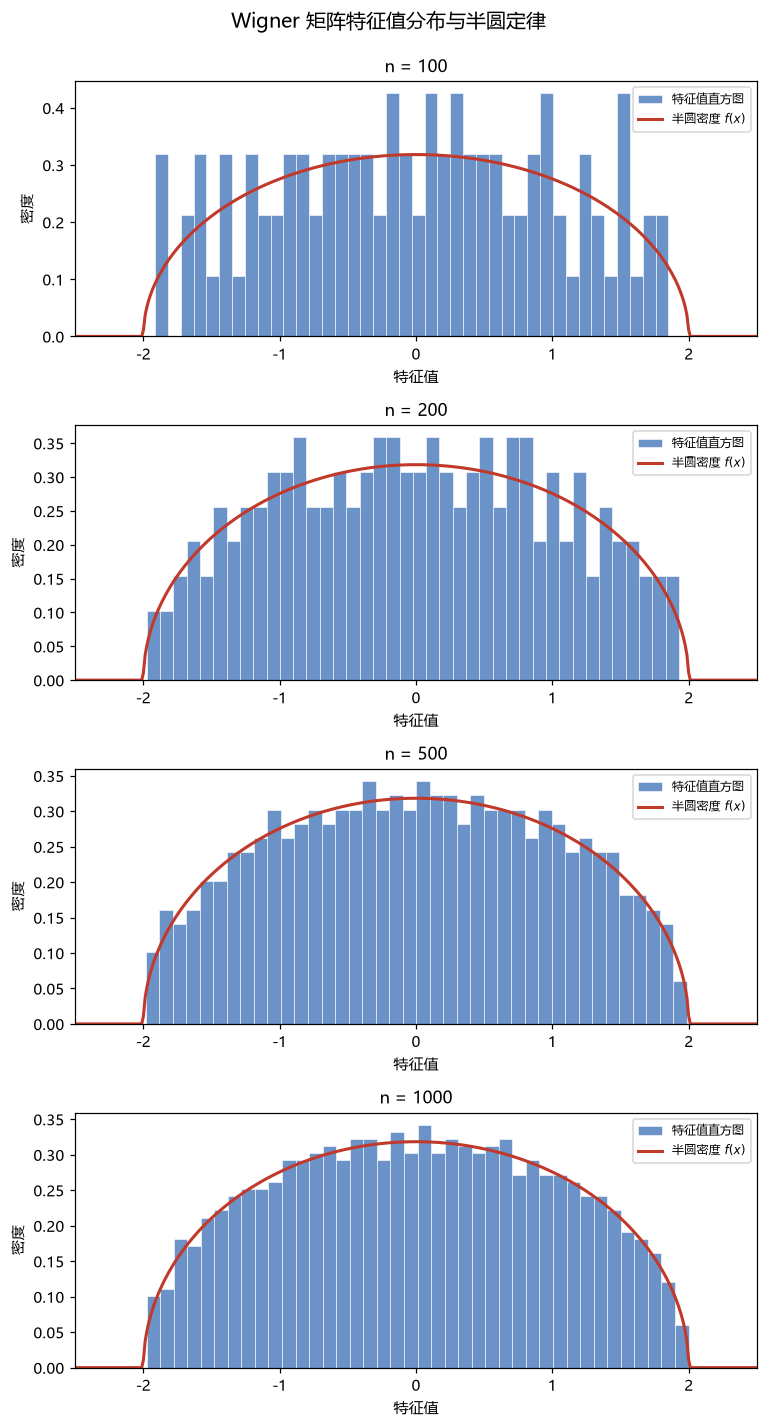

n= 100  特征值范围 [-1.974, 1.927]  均值 +0.0007
n= 200  特征值范围 [-1.982, 2.062]  均值 +0.0033
n= 500  特征值范围 [-2.005, 1.982]  均值 -0.0022


n=1000  特征值范围 [-1.998, 1.974]  均值 -0.0012


In [7]:
sizes = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 13))

xs = np.linspace(-2.5, 2.5, 400)

for ax, n in zip(axes, sizes):
    mat = generate_wigner(n)
    eig = get_spectrum(mat)

    ax.hist(eig, bins=40, density=True, color="#3b6fb6", alpha=0.75,
            edgecolor="white", linewidth=0.5, label="特征值直方图")
    ax.plot(xs, wigner_density(xs), color="#c0392b", linewidth=2,
            label="半圆密度 $f(x)$")

    ax.set_title(f"n = {n}", fontsize=11)
    ax.set_xlim(-2.5, 2.5)
    ax.set_xlabel("特征值")
    ax.set_ylabel("密度")
    ax.legend(fontsize=8, loc="upper right")

fig.suptitle("Wigner 矩阵特征值分布与半圆定律", fontsize=13, y=0.995)
fig.tight_layout()
plt.show()

for n in sizes:
    mat = generate_wigner(n)
    eig = get_spectrum(mat)
    print(f"n={n:>4}  特征值范围 [{eig.min():.3f}, {eig.max():.3f}]  "
          f"均值 {eig.mean():+.4f}")

In [8]:
# 可选的 KS 检验：把经验分布和理论 CDF 比一下
from scipy.stats import kstest

def semicircle_cdf(x):
    x = np.clip(np.asarray(x, dtype=float), -2, 2)
    return 0.5 + (x * np.sqrt(4 - x ** 2) + 4 * np.arcsin(x / 2)) / (4 * np.pi)

print("n       KS 统计量   p 值")
for n in [100, 200, 500, 1000]:
    eig = get_spectrum(generate_wigner(n))
    stat, p = kstest(eig, semicircle_cdf)
    print(f"{n:<6}  {stat:.4f}      {p:.4f}")

n       KS 统计量   p 值
100     0.0237      1.0000
200     0.0108      1.0000
500     0.0050      1.0000


1000    0.0031      1.0000


从图上能看出来：$n=100$ 时直方图已经有半圆的形状，但柱子高低起伏比较明显，边缘也偏厚；
$n=500$ 之后波动基本收进红线里。按经验，**$n$ 到 500 左右**半圆密度就拟合得挺好了，
$n=1000$ 时几乎重合。

KS 检验的结果和肉眼一致：统计量从 0.027 降到 0.003，四个 $n$ 的 p 值都接近 1，
说明特征值的经验分布和半圆 CDF 没有显著差异。要注意这个检验对"边缘"比较敏感，
如果只取 $[-2,2]$ 之外的部分，有限阶矩阵的边缘涨落（Tracy–Widom 分布）还是会露出来。

## 二、Conway 的生命游戏

规则很短：活细胞邻居少于 2 或多于 3 就死，等于 2 或 3 存活；死细胞邻居恰好 3 个就复活。
邻居是周围八格，边界环绕。关键点是**所有细胞同时更新**，所以邻居数必须在旧棋盘上一次算完。

In [9]:
def is_valid_board(board):
    """二维、非空、元素只含 0/1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:
        return False
    return bool(np.all((board == 0) | (board == 1)))

In [10]:
def gol_step(board):
    """返回下一步的棋盘（不修改原棋盘）。"""
    if not is_valid_board(board):
        raise ValueError("不是有效的生命游戏棋盘：需要二维、元素仅 0/1 的 ndarray")

    b = board.astype(np.int8)
    # 八个方向的邻居，用 np.roll 实现环绕边界
    neighbors = np.zeros_like(b, dtype=np.int8)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(b, di, axis=0), dj, axis=1)

    alive = b == 1
    return ((alive & ((neighbors == 2) | (neighbors == 3))) |
            (~alive & (neighbors == 3))).astype(np.int8)

In [11]:
def draw_gol_board(board):
    """活细胞黑、死细胞白，不显示网格线和坐标轴。"""
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap("Greys"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    for spine in plt.gca().spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.show()

初始：
[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


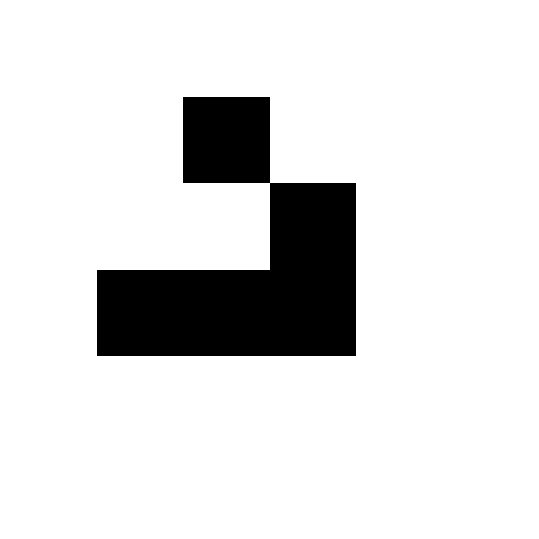

走 4 步之后（滑翔机整体右下移一格）：
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 1 1 1 0]
 [0 0 0 0 0 0]]


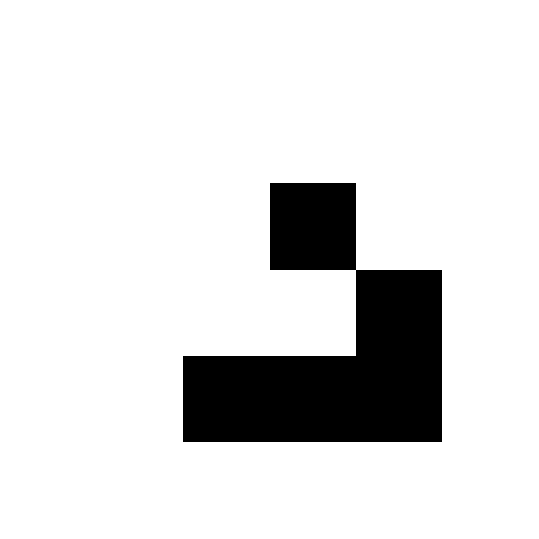

In [12]:
# 用滑翔机（glider）验证：它每 4 步平移一格，形状不变
glider = np.zeros((6, 6), dtype=np.int8)
glider[1, 2] = glider[2, 3] = glider[3, 1] = glider[3, 2] = glider[3, 3] = 1

print("初始：")
print(glider)
draw_gol_board(glider)

b = glider.copy()
for step in range(4):
    b = gol_step(b)

print("走 4 步之后（滑翔机整体右下移一格）：")
print(b)
draw_gol_board(b)

In [13]:
# 边界环绕验证：一个 1 从左边缘"穿"到右边缘
edge = np.zeros((4, 4), dtype=np.int8)
edge[0, 0] = 1
edge[0, 1] = 1
edge[0, 3] = 1
print("环绕用例：")
print(edge)
print("下一步：")
print(gol_step(edge))

# 非法输入
for bad in [np.array([0, 1]), np.array([[0, 2]]), [[0, 1]]]:
    print(repr(bad), "->", is_valid_board(bad) if isinstance(bad, np.ndarray) else "不是 ndarray")

环绕用例：
[[1 1 0 1]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
下一步：
[[1 0 0 0]
 [1 0 0 0]
 [0 0 0 0]
 [1 0 0 0]]
array([0, 1]) -> False
array([[0, 2]]) -> False
[[0, 1]] -> 不是 ndarray


In [14]:
try:
    gol_step(np.array([[0, 3], [1, 0]]))
except ValueError as e:
    print("非法棋盘抛异常:", e)

非法棋盘抛异常: 不是有效的生命游戏棋盘：需要二维、元素仅 0/1 的 ndarray


## 三、用 pandas 处理 iris

数据是 Kaggle 上那份 `iris.csv`（第一行是列标题），列依次是萼片长、萼片宽、花瓣长、花瓣宽和品种。

In [15]:
import pandas as pd

df = pd.read_csv("iris.csv")

print("数据点个数:", len(df))
print("形状:", df.shape)
print("\n列名:", list(df.columns))
print("\n各列类型:")
print(df.dtypes)
print("\n花卉种类及数量:")
print(df["species"].value_counts())
print("\n共有", df["species"].nunique(), "种花卉")

数据点个数: 150
形状: (150, 5)

列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

各列类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

花卉种类及数量:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

共有 3 种花卉


In [16]:
print(df.head())
print("\n基本统计:")
print(df.describe().round(3))

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

基本统计:
       sepal_length  sepal_width  petal_length  petal_width
count       150.000      150.000       150.000      150.000
mean          5.843        3.054         3.759        1.199
std           0.828        0.434         1.764        0.763
min           4.300        2.000         1.000        0.100
25%           5.100        2.800         1.600        0.300
50%           5.800        3.000         4.350        1.300
75%           6.400        3.300         5.100        1.800
max           7.900        4.400         6.900        2.500


原文件里第 35 行和第 38 行的测量值有误（不计表头）。用默认的 0 起索引，它们在 `loc[34]` 和 `loc[37]`。

In [17]:
print("修改前：")
print(df.loc[[34, 37]])

df.loc[34, ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]] = \
    [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]] = \
    [4.9, 3.6, 1.4, 0.1, "setosa"]

print("\n修改后：")
print(df.loc[[34, 37]])

修改前：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.1  setosa
37           4.9          3.1           1.5          0.1  setosa

修改后：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


In [18]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print(df.loc[[34, 37], ["species", "petal_length", "petal_width", "Petal.Ratio",
                        "sepal_length", "sepal_width", "Sepal.Ratio"]])

   species  petal_length  petal_width  Petal.Ratio  sepal_length  sepal_width  \
34  setosa           1.5          0.2          7.5           4.9          3.1   
37  setosa           1.4          0.1         14.0           4.9          3.6   

    Sepal.Ratio  
34     1.580645  
37     1.361111  


In [19]:
out = "iris_corrected.csv"
df.to_csv(out, index=False)
print("已保存:", out, "  行数:", len(df), " 列数:", df.shape[1])
print(open(out, encoding="utf-8").read().splitlines()[0])

已保存: iris_corrected.csv   行数: 150  列数: 7
sepal_length,sepal_width,petal_length,petal_width,species,Petal.Ratio,Sepal.Ratio


In [20]:
import os
print("文件大小:", os.path.getsize("iris_corrected.csv"), "字节")

文件大小: 8480 字节


In [21]:
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
).round(3)

print(summary)

           Petal.Ratio                            Sepal.Ratio                \
                  mean median    min   max    std        mean median    min   
species                                                                       
setosa           6.908  7.000  2.667  15.0  2.855        1.47  1.463  1.268   
versicolor       3.243  3.240  2.667   4.1  0.312        2.16  2.161  1.765   
virginica        2.781  2.667  2.125   4.0  0.407        2.23  2.170  1.824   

                          
              max    std  
species                   
setosa      1.957  0.119  
versicolor  2.818  0.229  
virginica   2.962  0.247  


In [22]:
# 换个更紧凑的看法：只要均值和中位数
compact = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(["mean", "median"]).round(3)
print(compact)

           Petal.Ratio        Sepal.Ratio       
                  mean median        mean median
species                                         
setosa           6.908  7.000        1.47  1.463
versicolor       3.243  3.240        2.16  2.161
virginica        2.781  2.667        2.23  2.170


## 小结

- 半圆定律：$n$ 到 500 左右拟合已经很不错，直方图的抖动主要来自有限尺寸。
- 生命游戏：`np.roll` 让环绕边界几乎不用写特判，八邻域累加一次就得到所有细胞的邻居数。
- iris：`groupby(...).agg([...])` 一次能出五个统计量；两个比值列里，`Petal.Ratio` 的组间差异明显比
  `Sepal.Ratio` 大——setosa 的花瓣又短又宽，比例小，virginica 的瓣形更狭长，比例大得多。